![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 03 | Evaluation and Interpretation

*Project 2 — Machine Learning: From Data to Predictions*

**Team:**
**Dataset:**

---

**This notebook is your report.** It is read on its own, by someone who has not seen notebooks 01 and 02, so it needs the prose as much as the code: the question, the final model, how good it is, where it fails, what drives it, and how far to trust it.

> **Done when:** someone who has never met your project can read this top to bottom and understand what you predicted, how well, compared with what, and where the model should not be used.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
## 1. The question and the final model

The framing from notebook 01 and the choice from notebook 02, in a few sentences. Then refit the final pipeline on the whole training set.

**The question:** a Portuguese bank calls clients to sell them a term deposit. Before a client gets called, I predict if they'll subscribe. That way the marketing team can call the likely ones first and skip the ones who'll probably say no.

**The data:** 41,176 phone contacts from May 2008 to November 2010 (UCI Bank Marketing), after removing 12 duplicates. `duration` (the length of the call) is dropped, because you only know it after the call.

**Target and metric:** `y` = did the client subscribe, positive class `yes`. Only 11.3% said yes. A missed yes (a lost sale) is worse than a wasted call, and accuracy is useless here: just saying "no" to everyone already gives 88.7%. So I compare the models with **F1** and also look at recall.

**Baseline:** calling everyone ("always yes") gets F1 = 0.203.

**The final model** (picked in notebook 02 out of logistic regression, decision tree, random forest and gradient boosting):

- `HistGradientBoostingClassifier` with `class_weight="balanced"` and default settings
- all columns except `duration`, `housing` and `loan`, with a "contacted before" flag instead of `pdays`
- threshold **0.60**: a client gets called if the predicted probability is at least 0.60

Fitting it on the whole training set (80% of the data, the test set is the other 20%):

In [2]:
from sklearn.metrics import f1_score, recall_score, precision_score, accuracy_score
from sklearn.inspection import permutation_importance
import joblib

X_train, X_test, y_train, y_test = split_data(clean_data(load_data()))

model = final_pipeline().fit(X_train, y_train)
model

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function add...t 0x16be2a200>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,None
,kw_args,"{'contacted_flag': True, 'drop': ('housing', ...)}"


---
## 2. Test once

The final model on the test set, **once**. Compare the score with the cross-validated estimate and with the baseline. If it is much worse than the estimate, say what that tells you.

First the cross-validated F1 at the chosen threshold on the training set, so I know what to expect and how much it jumps around:

In [3]:
cv_f1 = cv_scores_at_threshold(final_pipeline, X_train, y_train, make_cv(), FINAL_THRESHOLD)
print("F1 per fold:", cv_f1.round(3))
print(f"cross-validated F1: {cv_f1.mean():.3f} ± {cv_f1.std():.3f}")

F1 per fold: [0.498 0.489 0.478 0.515 0.502]
cross-validated F1: 0.496 ± 0.012


Now the test set, once:

In [4]:
from sklearn.dummy import DummyClassifier

proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= FINAL_THRESHOLD).astype(int)

baseline = DummyClassifier(strategy="constant", constant=1).fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

def scores(y_true, y_pred):
    return [f1_score(y_true, y_pred), recall_score(y_true, y_pred),
            precision_score(y_true, y_pred), accuracy_score(y_true, y_pred)]

pd.DataFrame({"final model": scores(y_test, pred), "baseline (always yes)": scores(y_test, baseline_pred)},
             index=["F1", "recall", "precision", "accuracy"]).round(3)

,final model,baseline (always yes)
F1,0.519,0.203
recall,0.609,1.000
precision,0.453,0.113
accuracy,0.873,0.113


- test F1 **0.519**, cross-validated 0.496 ± 0.012. The test score is a bit better, but still pretty close to the range of the folds (0.478 to 0.515). So no sign that the model only worked on the training data
- the baseline gets 0.203 on the test set, so the model is about 2.5 times better
- the model finds 61% of the subscribers (recall), and 45% of the clients it would call actually say yes. When calling everyone it's only 11%

---
## 3. Where it goes wrong

Classification: the confusion matrix and the per-class results, at your chosen threshold. Regression: the residuals, and where they are largest. Look at a few of the worst predictions and say what they have in common.

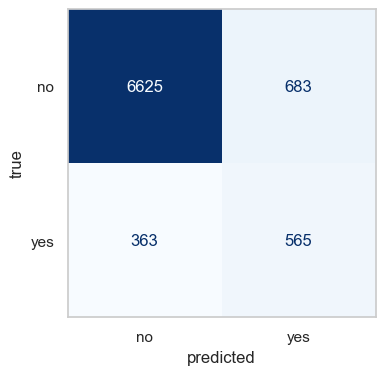

,no,yes
precision,0.948,0.453
recall,0.907,0.609
F1,0.927,0.519


In [5]:
plot_errors(y_test, pred)

pd.DataFrame({label: [precision_score(y_test, pred, pos_label=value),
                      recall_score(y_test, pred, pos_label=value),
                      f1_score(y_test, pred, pos_label=value)]
              for label, value in [("no", 0), ("yes", 1)]},
             index=["precision", "recall", "F1"]).round(3)

Out of 8,236 test clients the model would call 1,248:

- 565 of them subscribe (found), 683 don't (wasted calls)
- 363 subscribers get missed, that's 39% of all subscribers
- 6,625 clients are correctly skipped

### Where it works and where it doesn't

Let's look at the errors in groups. `results` has every test client with the real answer, the prediction and the probability:

In [6]:
results = X_test.assign(y=y_test, pred=pred, proba=proba)
results["age_group"] = pd.cut(results["age"], [0, 25, 30, 40, 50, 60, 120])

segment_table(results, "nr.employed")

,clients,yes,share called,recall,precision
nr.employed,,,,,
4963.6,119.0,60.0,0.891,0.950,0.538
4991.6,146.0,74.0,0.849,0.959,0.573
5008.7,128.0,75.0,0.992,1.000,0.591
5017.5,215.0,99.0,0.995,0.990,0.458
5023.5,35.0,16.0,1.000,1.000,0.457
5076.2,332.0,126.0,0.988,0.992,0.381
5099.1,1695.0,228.0,0.173,0.500,0.388
5176.3,2.0,0.0,0.000,0.000,0.000
5191.0,1586.0,54.0,0.000,0.000,0.000


This is the most important table. `nr.employed` is an economy number, and every value stands for a time period. The model basically splits the periods into two groups:

- in the periods with low values (≤ 5076.2, the later and worse economic times) way more people subscribed, and the model calls pretty much everyone (85–100%). Recall is ~100% there
- in the periods 5191.0 and 5228.1 the model calls **nobody**. 211 subscribers in the test set are in these two periods and the model misses every single one of them
- only in the period 5099.1 does the model really decide client by client (calls 17%, finds 50%)

So a big part of what the model does isn't "which client?", it's "which period?".

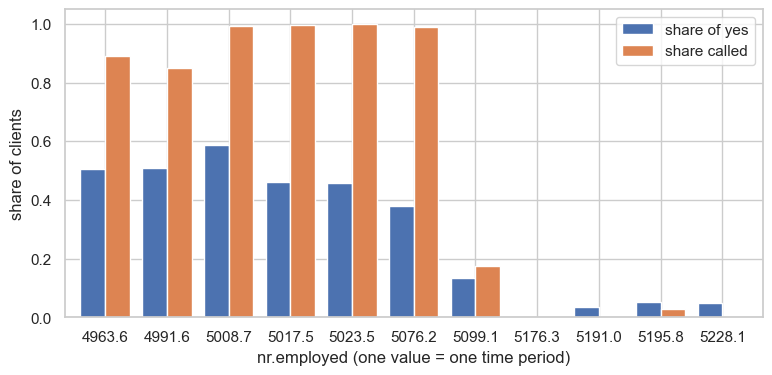

In [7]:
shares = results.groupby("nr.employed")[["y", "pred"]].mean().rename(columns={"y": "share of yes", "pred": "share called"})

ax = shares.plot(kind="bar", figsize=(9, 4), color=["#4C72B0", "#DD8452"], width=0.8)
ax.set_xlabel("nr.employed (one value = one time period)")
ax.set_ylabel("share of clients")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=0)
plt.show()

The chart shows the same thing: where the share of yes is high, the model calls almost everyone, and where it's low, it calls almost nobody.

Some other groups:

In [8]:
segment_table(results, "poutcome")

,clients,yes,share called,recall,precision
poutcome,,,,,
failure,837.0,127.0,0.297,0.724,0.369
nonexistent,7120.0,629.0,0.103,0.480,0.411
success,279.0,172.0,0.946,0.994,0.648


In [9]:
segment_table(results, "contact")

,clients,yes,share called,recall,precision
contact,,,,,
cellular,5196.0,764.0,0.213,0.669,0.462
telephone,3040.0,164.0,0.046,0.329,0.383


In [10]:
segment_table(results, "age_group")

,clients,yes,share called,recall,precision
age_group,,,,,
"(0, 25]",328.0,62.0,0.378,0.839,0.419
"(25, 30]",1106.0,153.0,0.212,0.660,0.430
"(30, 40]",3312.0,360.0,0.117,0.542,0.505
"(40, 50]",2021.0,151.0,0.080,0.464,0.432
"(50, 60]",1302.0,123.0,0.138,0.561,0.383
"(60, 120]",167.0,79.0,0.964,0.987,0.484


- `poutcome`: if the last campaign was a success, the model calls 95% of them and finds 99% of the subscribers. For clients who were never contacted before (most of them) recall is only 48%
- `contact`: clients with a landline (`telephone`) almost never get called (5%), so the model only finds 33% of the subscribers there
- age: the young (≤ 25) and old (> 60) clients get found really well (84% and 99%). In the middle groups (30–60) recall is only 46–56%

### The worst mistakes

The subscribers the model was most sure would say no:

In [11]:
results[(results["y"] == 1) & (results["pred"] == 0)].sort_values("proba").head(8)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,pred,proba,age_group
18394,42,self-employed,married,university.degree,no,yes,no,telephone,jul,thu,14,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,1,0,0.046182,"(40, 50]"
17284,59,retired,married,high.school,no,yes,no,cellular,jul,fri,17,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,1,0,0.053823,"(50, 60]"
18845,58,blue-collar,married,basic.9y,no,yes,no,cellular,aug,mon,1,999,0,nonexistent,1.4,93.444,-36.1,4.970,5228.1,1,0,0.100674,"(50, 60]"
12264,34,admin.,divorced,university.degree,no,no,no,telephone,jul,thu,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,1,0,0.113641,"(30, 40]"
17918,48,technician,married,professional.course,no,yes,no,telephone,jul,tue,11,999,0,nonexistent,1.4,93.918,-42.7,4.961,5228.1,1,0,0.122455,"(40, 50]"
6520,57,blue-collar,divorced,basic.9y,no,yes,no,telephone,may,wed,2,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,1,0,0.130497,"(50, 60]"
75,41,blue-collar,divorced,basic.4y,unknown,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,1,0,0.145924,"(40, 50]"
18284,32,admin.,married,university.degree,no,yes,no,telephone,jul,wed,8,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,1,0,0.146025,"(30, 40]"


All of them are from the periods 5228.1 or 5191.0 and were never contacted before (`poutcome` = `nonexistent`). 6 of the 8 were called on a landline, and some of them got called 8 to 17 times in this campaign. That's exactly the profile the model learned as "no".

And the clients the model was most sure would say yes, but didn't:

In [12]:
results[(results["y"] == 0) & (results["pred"] == 1)].sort_values("proba", ascending=False).head(8)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,pred,proba,age_group
39353,33,services,single,high.school,no,yes,no,cellular,mar,fri,2,6,1,success,-1.8,93.369,-34.8,0.636,5008.7,0,1,0.955881,"(30, 40]"
39308,28,admin.,single,university.degree,no,yes,no,cellular,mar,thu,1,9,1,success,-1.8,93.369,-34.8,0.643,5008.7,0,1,0.955015,"(25, 30]"
40288,60,retired,married,professional.course,no,yes,yes,cellular,jul,thu,4,6,2,success,-1.7,94.215,-40.3,0.899,4991.6,0,1,0.954909,"(50, 60]"
40173,26,technician,single,university.degree,no,no,no,cellular,jul,fri,2,6,1,success,-1.7,94.215,-40.3,0.861,4991.6,0,1,0.954754,"(25, 30]"
40857,30,technician,unknown,university.degree,no,no,no,cellular,oct,fri,2,16,1,success,-1.1,94.601,-49.5,0.942,4963.6,0,1,0.954338,"(25, 30]"
40040,30,admin.,single,university.degree,no,yes,no,cellular,jul,tue,2,3,1,success,-1.7,94.215,-40.3,0.797,4991.6,0,1,0.953735,"(25, 30]"
40044,30,admin.,single,university.degree,no,no,no,cellular,jul,tue,1,3,2,success,-1.7,94.215,-40.3,0.797,4991.6,0,1,0.953735,"(25, 30]"
40160,32,admin.,single,university.degree,no,yes,no,cellular,jul,thu,2,6,1,success,-1.7,94.215,-40.3,0.846,4991.6,0,1,0.952798,"(30, 40]"


All of them had a success in the last campaign and were called on their mobile in one of the later periods. On paper the best profile you can get, but they still said no.

---
## 4. What drives the predictions

Permutation importance on the test set, or an equivalent. Strongly related features share their importance, so read the ranking with care, and translate it into business terms.

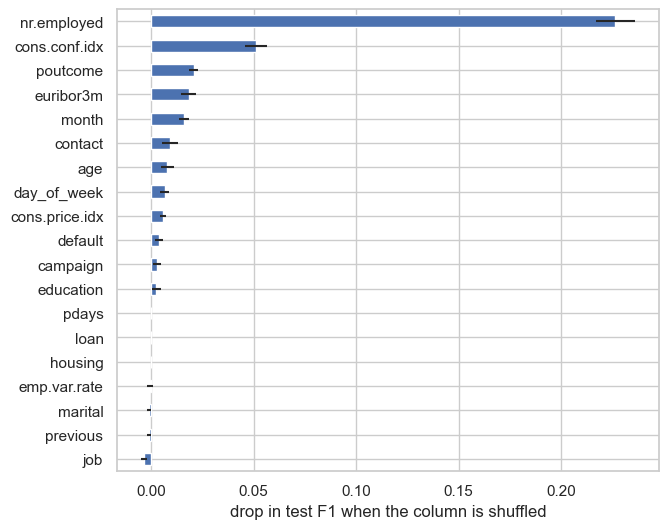

In [13]:
importance = permutation_importance(model, X_test, y_test, scoring=f1_at_threshold(FINAL_THRESHOLD),
                                    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({"mean": importance.importances_mean, "std": importance.importances_std},
                          index=X_test.columns).sort_values("mean")

ax = importance["mean"].plot(kind="barh", xerr=importance["std"], figsize=(7, 6), color="#4C72B0")
ax.set_xlabel("drop in test F1 when the column is shuffled")
plt.show()

Every column gets shuffled 10 times on the test set, and the chart shows how much the test F1 drops. The bigger the drop, the more the model depends on that column. (`housing`, `loan` and `pdays` are at 0 because the model doesn't use them.)

- **`nr.employed` is by far the most important** (F1 drops by 0.23). Together with `cons.conf.idx` (0.05) and `euribor3m` (0.02), the economy is what drives the model the most. Fits what I found in the errors: the model mainly recognises the period
- `emp.var.rate` is at 0, but that doesn't mean the employment rate doesn't matter. It moves almost exactly like `nr.employed` (correlation 0.91), so when one of them gets shuffled the other still has the same info. The economy columns share their importance
- after the economy: `poutcome` (how the last campaign went), `month`, `contact` and `age`
- `job` is slightly negative, so it doesn't help on the test set, even though students and retired people say yes more often. Probably `age` already covers that

**What this means for the bank:** whether a client subscribes depends a lot more on *when* they get called than on *who* they are. In the bad economic times (low employment, low interest rates) way more clients took a term deposit. Within a period, the best signs are a success in the last campaign, a mobile number and being young or retired.

---
## 5. Save, reload, predict

Save the fitted pipeline (and the threshold) with `joblib` into `models/`, reload it, and predict for a few new rows. This is your demo on Friday.

In [14]:
path = MODELS / "bank_marketing_model.joblib"
joblib.dump({"pipeline": model, "threshold": FINAL_THRESHOLD}, path)
print("Saved to", path.name)

Saved to bank_marketing_model.joblib


In [15]:
saved = joblib.load(path)

new_clients = X_test.sample(5, random_state=0)      # stand-ins for new clients
proba_new = saved["pipeline"].predict_proba(new_clients)[:, 1]

new_clients[["age", "job", "contact", "poutcome", "nr.employed"]].assign(
    probability=proba_new.round(3),
    decision=np.where(proba_new >= saved["threshold"], "call", "skip"))

,age,job,contact,poutcome,nr.employed,probability,decision
22212,46,unemployed,cellular,nonexistent,5228.1,0.181,skip
7208,56,technician,telephone,nonexistent,5191.0,0.240,skip
21914,48,admin.,cellular,nonexistent,5228.1,0.290,skip
6461,35,services,telephone,nonexistent,5191.0,0.182,skip
39636,59,admin.,cellular,nonexistent,5008.7,0.904,call


The saved file has the whole pipeline and the threshold, so raw rows go in (same columns as in the CSV, without `duration` and `y`) and a probability comes out. Works with a completely made-up client too:

In [16]:
client = pd.DataFrame([{
    "age": 67, "job": "retired", "marital": "married", "education": "high.school",
    "default": "no", "housing": "no", "loan": "no", "contact": "cellular",
    "month": "oct", "day_of_week": "tue", "campaign": 1, "pdays": 999, "previous": 0,
    "poutcome": "nonexistent", "emp.var.rate": -3.4, "cons.price.idx": 92.431,
    "cons.conf.idx": -26.9, "euribor3m": 0.754, "nr.employed": 5017.5,
}])
p = saved["pipeline"].predict_proba(client)[0, 1]
print(f"probability of yes: {p:.3f} -> {'call' if p >= saved['threshold'] else 'skip'}")

probability of yes: 0.812 -> call


Same client, but called in one of the "good" economic periods (July, high interest rate), and then the same again with a success in the last campaign:

In [17]:
good_period = {"month": "jul", "emp.var.rate": 1.4, "cons.price.idx": 93.918,
               "cons.conf.idx": -42.7, "euribor3m": 4.962, "nr.employed": 5228.1}
past_success = {"poutcome": "success", "previous": 1, "pdays": 6}

versions = pd.concat([client,
                      client.assign(**good_period),
                      client.assign(**good_period, **past_success)], ignore_index=True)
p = saved["pipeline"].predict_proba(versions)[:, 1]
pd.DataFrame({"called": ["bad period (Oct)", "good period (Jul)", "good period + past success"],
              "probability": p.round(3),
              "decision": np.where(p >= saved["threshold"], "call", "skip")})

,called,probability,decision
0,bad period (Oct),0.812,call
1,good period (Jul),0.369,skip
2,good period + past success,0.692,call


Same person, completely different answer depending on *when* they're called. Only the success in the last campaign gets them back over the threshold.

---
## 6. Conclusions and limitations

Would you use this model, and for what? Where should it not be trusted? What would you do with another week? Knowing the limits of your own model is part of the grade.

### One more check: a future campaign

The split was random, so the training and test set come from the same periods. But the bank would use the model on a *future* campaign. To see how it does there, I sort the **training** rows by date (the file is sorted by date), train on the oldest 80% and test on the newest 20%. The test set isn't used for this.

In [18]:
by_date = X_train.sort_index()
y_by_date = y_train.loc[by_date.index]
cut = int(len(by_date) * 0.8)

future_model = final_pipeline().fit(by_date.iloc[:cut], y_by_date.iloc[:cut])
future_pred = future_model.predict_proba(by_date.iloc[cut:])[:, 1] >= FINAL_THRESHOLD
y_future = y_by_date.iloc[cut:]
future_baseline = DummyClassifier(strategy="constant", constant=1).fit(by_date.iloc[:cut], y_by_date.iloc[:cut])

print(f"share of yes: older {y_by_date.iloc[:cut].mean():.1%}, newer {y_future.mean():.1%}")
print(f"F1 on the newer calls: model {f1_score(y_future, future_pred):.3f}, "
      f"always yes {f1_score(y_future, future_baseline.predict(by_date.iloc[cut:])):.3f}")

share of yes: older 6.5%, newer 30.5%
F1 on the newer calls: model 0.398, always yes 0.468


On the newer calls the model only gets an F1 of 0.398, and just calling everyone would actually be better (0.468). The newer period had 30.5% yes instead of 6.5%, plus economy values the model had never seen. So the nice test score (0.519) only holds for clients from the same periods as the training data.

### Conclusions

**Would I use it?** Not as it is for a new campaign. On the random test set the model is clearly better than calling everyone (F1 0.519 vs 0.203): with 15% of the calls it reaches 61% of the subscribers. But most of that comes from recognising the economic period, and on newer calls it did worse than just calling everyone.

**What the bank can use right now** are the patterns behind it:

- clients where the last campaign was a success say yes about 65% of the time, so they should always get a call
- clients with a mobile number, students and retired people subscribe more often
- calling the same client over and over in one campaign rarely works
- in bad economic times (low interest rates, low employment) way more people take a term deposit, so that's when a campaign is worth it

**Where it shouldn't be trusted:**

- on a future campaign, especially when the economy looks different from 2008–2010
- in "good" economic periods (like 5191.0 and 5228.1), where it calls nobody and misses every subscriber
- for clients with a landline and no earlier contact, where it only finds a small part of the subscribers
- outside of this bank and Portugal: the data is from one Portuguese bank during the financial crisis

**With another week I would:**

- validate by time (train on older, test on newer) instead of randomly, and pick the model and threshold that way
- try a model without the economy columns, to see what the client data alone can do
- get the real cost of a call and the value of a term deposit from the bank, so the threshold can be picked with money instead of F1
- retrain the model regularly on the most recent campaigns

---
## Image option

If you chose the flower photos: evaluate the chosen model once on the test set; show the confusion matrix, per-class precision and recall, and a gallery of misclassified photos with a reading of why; save it as a `.keras` file, reload it and predict a photo it has never seen.